# 03 — The Spec War: same model, better food

**Status:** Day 5. OLS has no knobs to tune — the only lever is *what we feed
it*. Thursday's diagnostics produced three hypotheses; today each one fights
in the same arena (5-fold CV, identical seed) and every result lands in
`results/runs.csv` with its reason.

**Arena rules**
1. Same CV protocol for every spec — no spec gets an easier test.
2. Every run is logged with a one-line reason, or it doesn't count.
3. The champion must win *and* have a mechanism. A number without a story
   is luck; a story without a number is a guess.

## The challengers

| spec | change | hypothesis (from Thursday) |
|---|---|---|
| v1_full_pipeline | — (baseline, logged Wednesday) | — |
| S1_collapse_rare | categories with <10 houses → `Other` | kills the h=1.0 memorization levers |
| S2_no_outliers | v1 minus Ids {826, 524} | sensitivity probe: how much do the two Cook's leaders cost? **diagnostic only — deleting honest houses is not adoptable** |
| S3_drop_twins | drop GarageArea, 1stFlrSF, TotRmsAbvGrd | collinear twins steal credit unstably |
| S4_collapse_and_drop_twins | S1 + S3 combined | kitchen sink: do both fixes stack? |

## 1. Run the arena

In [1]:
import pandas as pd
import numpy as np

from house_prices.data import load_train
from house_prices.features import SPEC_FNS
from house_prices.train import fit_spec, log_run, RESULTS

train = load_train()
DIAGNOSTIC_ONLY = {"S2_no_outliers"}  # measured, never adopted

results = {}
for name, fn in SPEC_FNS.items():
    _, m = fit_spec(train, feature_fn=fn, spec_name=name)
    results[name] = m

# S2 is a data decision, not a feature function: v1 features, two houses withheld
kept = train[~train["Id"].isin([826, 524])]
_, m = fit_spec(kept, spec_name="S2_no_outliers")
results["S2_no_outliers"] = m

table = pd.DataFrame(results).T
table.columns = ["CV RMSE (usd)", "CV RMSLE (log)"]
table.round({"CV RMSE (usd)": 0, "CV RMSLE (log)": 5})

,CV RMSE (usd),CV RMSLE (log)
v1_full_pipeline,77885.0,0.15453
S1_collapse_rare,71996.0,0.15171
S3_drop_twins,78525.0,0.15491
S4_collapse_and_drop_twins,73695.0,0.15317
S2_no_outliers,84338.0,0.14818


## 2. Log every run (idempotently — re-running never double-books)

In [2]:
reasons = {
    "S1_collapse_rare": "Thursday: 1-house categories had leverage 1.0; collapse removes memorization",
    "S2_no_outliers": "SENSITIVITY ONLY (not adoptable): measures the pull of Cook's leaders 826/524",
    "S3_drop_twins": "Monday/Thursday: drop one collinear twin per r>=0.82 pair",
    "S4_collapse_and_drop_twins": "kitchen sink: do S1 and S3 stack?",
}
existing = set(pd.read_csv(RESULTS)["spec"]) if RESULTS.exists() else set()
for name in results:
    if name in existing:
        print(f"already logged, skipping: {name}")
        continue
    m = results[name]
    log_run(RESULTS, name, m["rmse"], m["rmsle"], reasons[name])
    print(f"logged: {name}")

pd.read_csv(RESULTS)

already logged, skipping: v1_full_pipeline
already logged, skipping: S1_collapse_rare
already logged, skipping: S3_drop_twins
already logged, skipping: S4_collapse_and_drop_twins
already logged, skipping: S2_no_outliers


,spec,cv_rmse_usd,cv_rmsle,notes
0,v1_full_pipeline,77885.38,0.15453,first OLS fit: ordinal + impute + log + one-hot
1,S1_collapse_rare,71996.26,0.15171,Thursday: 1-house categories had leverage 1.0;...
2,S3_drop_twins,78524.96,0.15491,Monday/Thursday: drop one collinear twin per r...
3,S4_collapse_and_drop_twins,73695.06,0.15317,kitchen sink: do S1 and S3 stack?
4,S2_no_outliers,84338.37,0.14818,SENSITIVITY ONLY (not adoptable): measures the...


## 3. Read the results

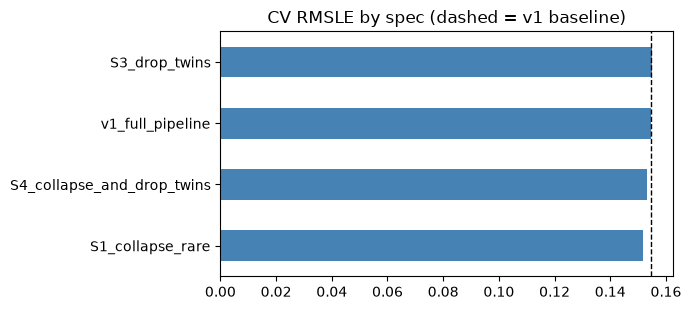

In [3]:
import matplotlib.pyplot as plt

legit = table.drop(index=list(DIAGNOSTIC_ONLY)).sort_values("CV RMSLE (log)")
ax = legit["CV RMSLE (log)"].plot.barh(figsize=(7, 3.2), color="steelblue")
ax.axvline(table.loc["v1_full_pipeline", "CV RMSLE (log)"], color="black", linewidth=1, linestyle="--")
ax.set_title("CV RMSLE by spec (dashed = v1 baseline)")
plt.tight_layout()

**The verdicts:**

- **S1 (collapse rare) — ADOPTED. 0.15453 → 0.15171 RMSLE, RMSE −$5,889.** Both
  metrics improved and the mechanism is the one Thursday exposed: the model
  stopped memorizing singletons and started generalizing. This is what a
  *correct fix* looks like — it wins on every ruler at once.
- **S2 (no outliers) — measured, rejected. RMSLE 0.14818 *looks* best, but its
  dollar RMSE is the worst of all ($84,338).** More importantly it's
  inadmissible: deleting two honest houses because they hurt the score is the
  exact "optimizing the number, not the learning" we banned this week. Its real
  value is the measurement: those two houses cost ~0.006 RMSLE, and S1 recovers
  improvement *while keeping them*. Fixing the cause, not the symptom.
- **S3 (drop twins) — hypothesis rejected. 0.15491, slightly worse than v1.**
  The collinearity was real but cheap: the twins carried a little predictive
  signal, and OLS's instability between them wasn't hurting out-of-fold
  accuracy. Lesson: a diagnosable pathology isn't always a performance problem.
- **S4 (S1+S3) — 0.15317, worse than S1 alone.** The kitchen sink dilutes the
  good fix with the bad one. Adding changes is not free; each needs its own
  evidence.

## 4. Champion: S1 — and a look at its coefficients

**Why S1 wins (the written justification):** best legitimate CV RMSLE
(0.15171), best legitimate CV RMSE ($71,996), keeps every honest house, and
the improvement has a named mechanism — Thursday's h=1.0 levers are gone. It
also made the model readable, which the table below demonstrates: no more
roof-material ghosts at the top.

In [4]:
from house_prices.features import build_features_collapse_rare

champion_name = "S1_collapse_rare"
feature_fn = SPEC_FNS[champion_name]
X, y = feature_fn(train)

from sklearn.linear_model import LinearRegression
champion = LinearRegression().fit(X, np.asarray(y))
coef = pd.Series(champion.coef_, index=X.columns)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
print("largest |coefficients| of the champion:")
print(top.round(3))
print("\n(compare 02_diagnostics section 5: RoofMatl_ClyTile at -2.34 is gone)")

largest |coefficients| of the champion:
MSZoning_C (all)       -0.342
Functional_Other       -0.220
Neighborhood_StoneBr    0.162
Utilities_Other        -0.157
Utilities_AllPub        0.157
Neighborhood_NridgHt    0.125
Neighborhood_MeadowV   -0.119
HouseStyle_Other       -0.114
MSZoning_RH             0.110
Neighborhood_Edwards   -0.109
dtype: float64

(compare 02_diagnostics section 5: RoofMatl_ClyTile at -2.34 is gone)


## 5. Serialize and reload-verify

The champion ships as a bundle: the fitted model + its spec name + its column
language. Saturday's `submission.py` looks the spec up in `SPEC_FNS`, rebuilds
the test features the same way, aligns columns, and predicts.

In [5]:
import joblib
from pathlib import Path

bundle = {
    "model": champion,
    "spec_name": champion_name,
    "columns": list(X.columns),
}
out = Path("../models/champion.joblib")
out.parent.mkdir(exist_ok=True)
joblib.dump(bundle, out)
print(f"saved {out} ({out.stat().st_size//1024} KB)")

saved ../models/champion.joblib (11 KB)


In [6]:
# reload in a fresh state, exactly like submission day will
import joblib, numpy as np
from house_prices.features import SPEC_FNS, align_columns, inverse_target

bundle = joblib.load("../models/champion.joblib")
X_check, _ = SPEC_FNS[bundle["spec_name"]](load_train())
preds_log = bundle["model"].predict(X_check[:5])
preds = inverse_target(preds_log)
assert np.all(np.isfinite(preds)) and (preds > 0).all()
print("reload verified — first 5 predictions:", )
print(np.round(preds, 0))

reload verified — first 5 predictions:
[208451. 194273. 217091. 177014. 300887.]
